# Trực quan hóa dữ liệu ô tô (Chợ Tốt)

Mỗi biểu đồ được lưu thành ảnh PNG trong thư mục `figures/` để đưa vào báo cáo.

**Lưu ý:** notebook này vẽ trên **dữ liệu thô** (`raw_data_oto.csv`), chỉ ép kiểu số, chưa xóa dòng trùng, chưa loại giá bất hợp lý hay giá trả trước/đặt cọc (các bước đó ở `preprocess_data.ipynb`). Vì vậy các con số như giá nhỏ nhất 0,36 triệu hay lớn nhất 40 tỷ là của dữ liệu thô; khi đưa vào báo cáo cần ghi rõ "dữ liệu thô".

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

# Bảng màu: 1 màu chủ đạo (xanh) cho đại lượng đơn, thang xanh nhạt->đậm cho độ lớn, cam để nhấn, xám cho phần phụ
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c3c2b7"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
})

def save(fig, name):
    fig.savefig(f"figures/{name}.png")
    plt.show()

def style_box(bp, color=BLUE):
    for b in bp["boxes"]:
        b.set(facecolor=color, alpha=0.85, edgecolor=color)
    for k in ("whiskers", "caps"):
        for x in bp[k]:
            x.set(color=GRAY)
    for m in bp["medians"]:
        m.set(color="white", linewidth=2)
    for f in bp["fliers"]:
        f.set(marker="o", markersize=2.5, markerfacecolor=GRAY, markeredgecolor="none", alpha=0.5)

## 1. Đọc dữ liệu thô và ép kiểu

In [2]:
# Chỉ "N/A" / "Đang cập nhật" là thiếu ở mọi cột. "Khác" chỉ là thiếu ở carseats (số chỗ không xác định)
# và tự thành NaN khi ép sang số bên dưới; ở các cột khác "Khác" là nhãn thật (giống preprocess_data.ipynb).
df = pd.read_csv("raw_data_oto.csv", na_values=["N/A", "Đang cập nhật"],
                 dtype={"mileage_v2": str, "price": str, "carseats": str})

for col in ["mileage_v2", "price", "carseats"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(".", "", regex=False), errors="coerce")

df["price_tr"] = df["price"] / 1e6          # triệu đồng
df["mfdate"] = pd.to_numeric(df["mfdate"], errors="coerce")  # "trước năm 1980" -> thiếu
df["age"] = 2026 - df["mfdate"]
df["mileage_k"] = df["mileage_v2"] / 1e3    # nghìn km
df = df.dropna(subset=["price_tr"])
print(df.shape)
df[["price_tr", "mileage_k", "mfdate", "carseats"]].describe().T

(14834, 17)


,count,mean,std,min,25%,50%,75%,max
price_tr,14834.0,605.239578,731.561738,0.360,282.25,459.0,685.0,39999.999999
mileage_k,13024.0,80.684884,95.931704,0.001,29.00,66.0,100.0,1000.000000
mfdate,14822.0,2019.230738,6.106774,1981.000,2016.00,2021.0,2024.0,2026.000000
carseats,11147.0,5.856194,1.758129,2.000,5.00,5.0,7.0,16.000000


## 2. Chất lượng dữ liệu: tỉ lệ giá trị thiếu
Cho thấy cột nào đáng tin để phân tích (`carorigin` thiếu nhiều nhất).

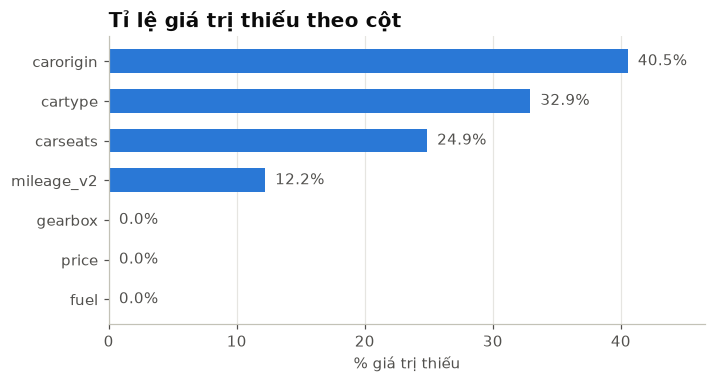

In [3]:
cols = ["carorigin", "cartype", "carseats", "mileage_v2", "gearbox", "fuel", "price"]
miss = (df[cols].isna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(miss.index, miss.values, color=BLUE, height=0.6)
for y, v in enumerate(miss.values):
    ax.text(v + 0.8, y, f"{v:.1f}%", va="center", color=INK2)
ax.set_xlim(0, miss.max() * 1.15)
ax.set_xlabel("% giá trị thiếu")
ax.set_title("Tỉ lệ giá trị thiếu theo cột")
ax.grid(axis="y", visible=False)
save(fig, "01_missing")

## 3. Cơ cấu thị trường: tình trạng, nhiên liệu, hộp số

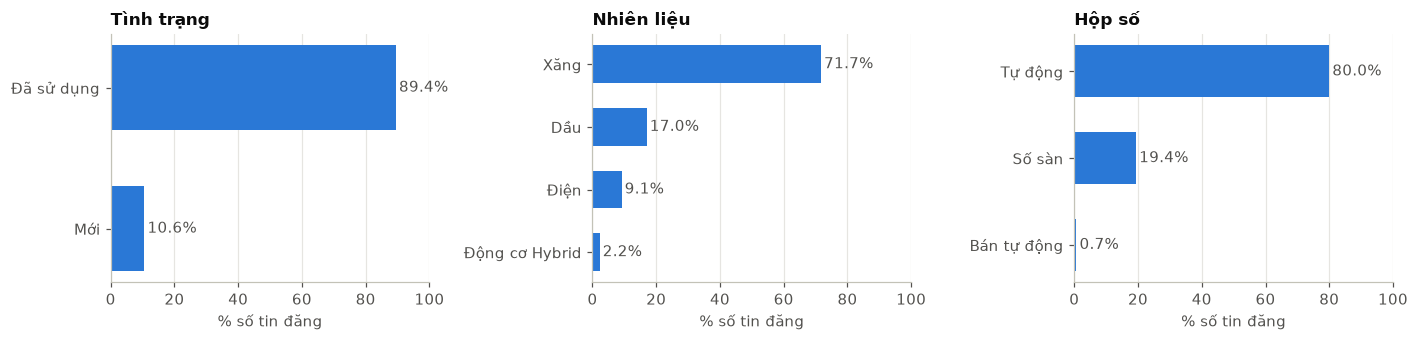

In [4]:
def share(ax, col, title):
    s = (df[col].value_counts(normalize=True) * 100).sort_values()
    ax.barh(s.index, s.values, color=BLUE, height=0.6)
    for y, v in enumerate(s.values):
        ax.text(v + 1, y, f"{v:.1f}%", va="center", color=INK2)
    ax.set_xlim(0, 100)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("% số tin đăng")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
share(axes[0], "condition_ad", "Tình trạng")
share(axes[1], "fuel", "Nhiên liệu")
share(axes[2], "gearbox", "Hộp số")
fig.tight_layout()
save(fig, "02_co_cau")

## 4. Thương hiệu: số tin đăng nhiều nhất

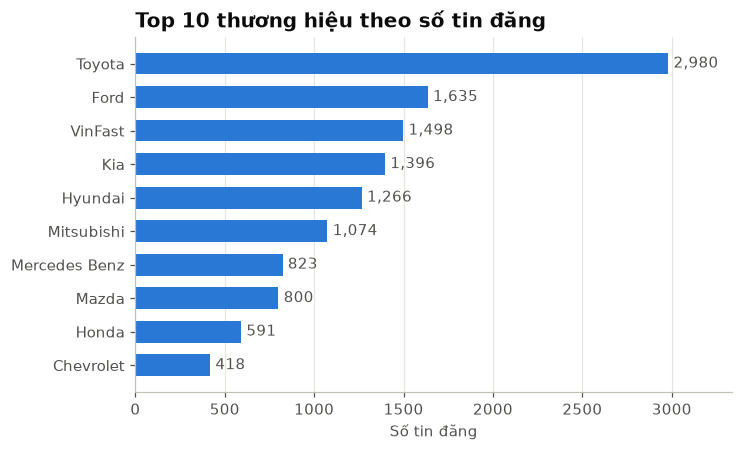

In [5]:
top = df["carbrand"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, color=BLUE, height=0.65)
for y, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, y, f"{v:,}", va="center", color=INK2)
ax.set_xlim(0, top.max() * 1.12)
ax.set_xlabel("Số tin đăng")
ax.set_title("Top 10 thương hiệu theo số tin đăng")
ax.grid(axis="y", visible=False)
save(fig, "03_top_hang")

## 5. Phân bố giá
Cắt ở phân vị 99% để vài xe siêu sang không làm lệch trục.

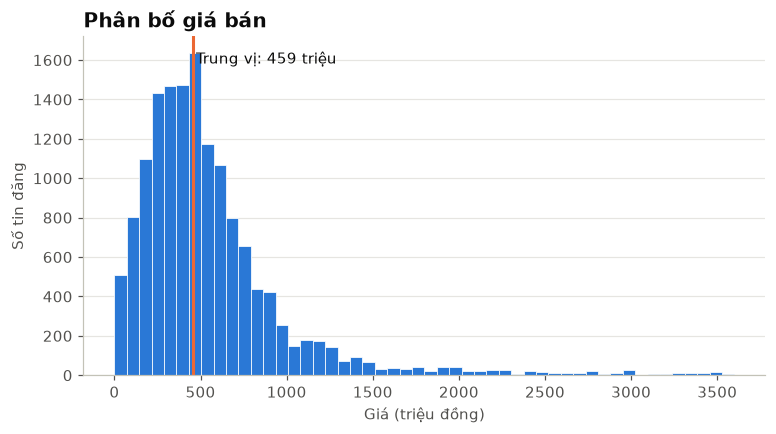

In [6]:
p99 = df["price_tr"].quantile(0.99)
d = df[df["price_tr"] <= p99]
med = df["price_tr"].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(d["price_tr"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(med, color=ORANGE, lw=2)
ax.text(med + 15, ax.get_ylim()[1] * 0.92, f"Trung vị: {med:,.0f} triệu", color=INK)
ax.set_xlabel("Giá (triệu đồng)")
ax.set_ylabel("Số tin đăng")
ax.set_title("Phân bố giá bán")
ax.grid(axis="x", visible=False)
save(fig, "04_phan_bo_gia")

## 6. Giá theo thương hiệu
Hộp (box) cho thấy trung vị (vạch trắng), khoảng tứ phân vị và độ phân tán (đã ẩn điểm ngoại lai); sắp xếp theo trung vị.

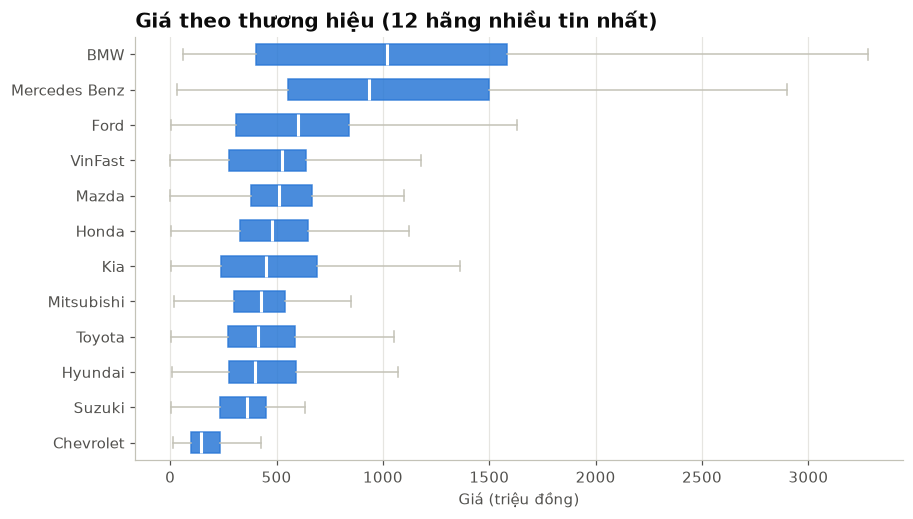

In [7]:
top12 = df["carbrand"].value_counts().head(12).index
order = df[df["carbrand"].isin(top12)].groupby("carbrand")["price_tr"].median().sort_values().index
data = [df.loc[df["carbrand"] == b, "price_tr"] for b in order]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, showfliers=False, widths=0.6, tick_labels=order)
style_box(bp)
ax.set_xlabel("Giá (triệu đồng)")
ax.set_title("Giá theo thương hiệu (12 hãng nhiều tin nhất)")
ax.grid(axis="y", visible=False)
save(fig, "05_gia_theo_hang")

## 7. Giá theo nhiên liệu và kiểu dáng

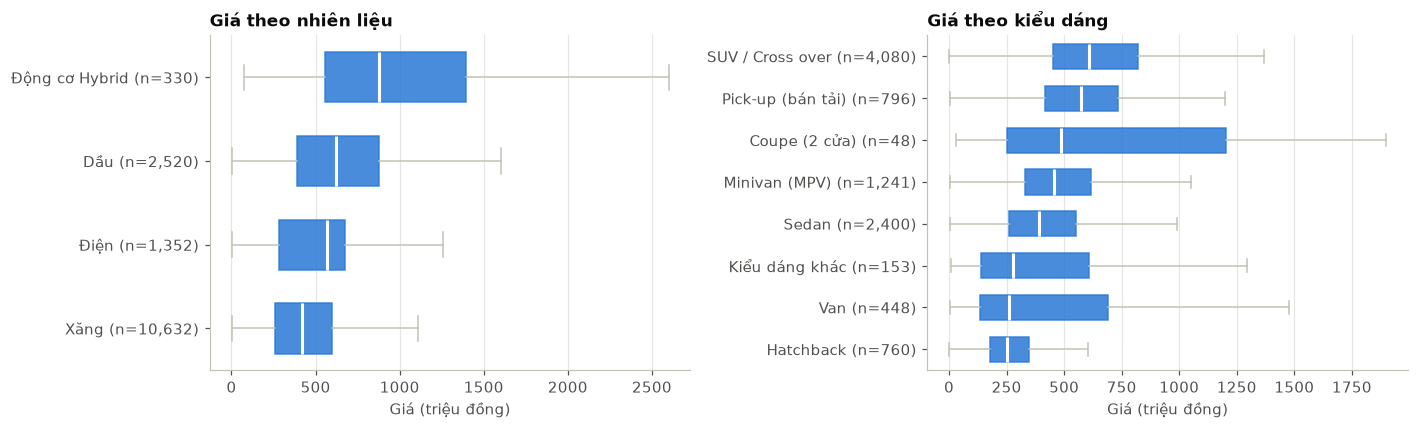

In [8]:
def box_by(ax, col, title, min_n=30):
    vc = df[col].value_counts()
    d = df[df[col].isin(vc[vc >= min_n].index)]
    order = d.groupby(col)["price_tr"].median().sort_values().index
    bp = ax.boxplot([d.loc[d[col] == k, "price_tr"] for k in order], orientation="horizontal",
                    patch_artist=True, showfliers=False, widths=0.6, tick_labels=[f"{k} (n={vc[k]:,})" for k in order])
    style_box(bp)
    ax.set_xlabel("Giá (triệu đồng)")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
box_by(axes[0], "fuel", "Giá theo nhiên liệu")
box_by(axes[1], "cartype", "Giá theo kiểu dáng")
fig.tight_layout()
save(fig, "06_gia_nhien_lieu_kieu_dang")

## 8. Giá theo hộp số và tình trạng

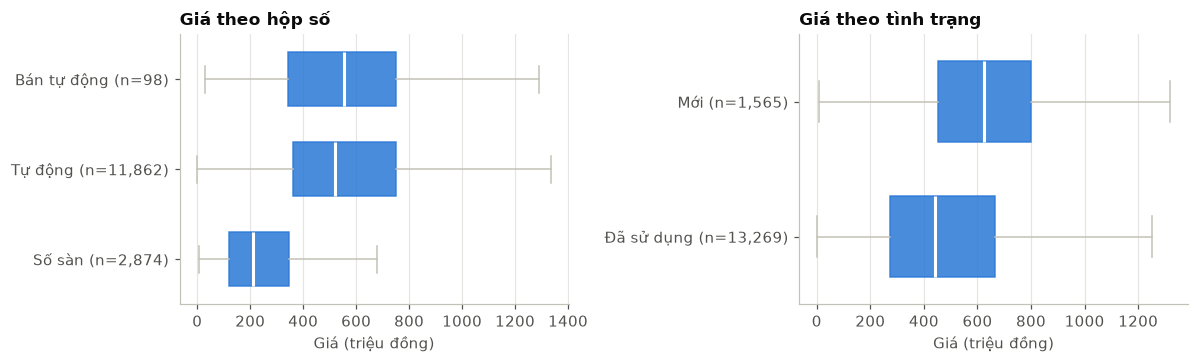

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
box_by(axes[0], "gearbox", "Giá theo hộp số")
box_by(axes[1], "condition_ad", "Giá theo tình trạng")
fig.tight_layout()
save(fig, "07_gia_hop_so_tinh_trang")

## 9. Giá theo năm sản xuất
Đường: giá trung vị mỗi năm. Chỉ lấy các năm có từ 30 tin trở lên để trung vị đủ tin cậy.

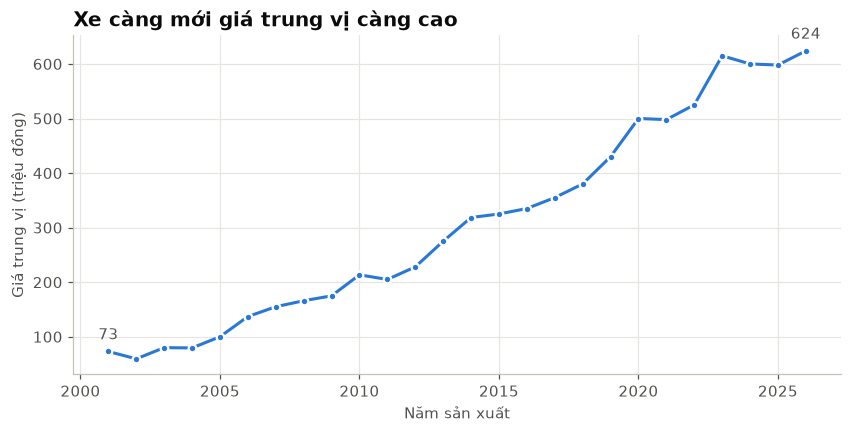

In [10]:
g = df.groupby("mfdate")["price_tr"].agg(["median", "count"])
g = g[g["count"] >= 30]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(g.index, g["median"], color=BLUE, lw=2, marker="o", markersize=5,
        markerfacecolor=BLUE, markeredgecolor="white", markeredgewidth=1.5)
ax.set_xlabel("Năm sản xuất")
ax.set_ylabel("Giá trung vị (triệu đồng)")
ax.set_title("Xe càng mới giá trung vị càng cao")
for i in (0, -1):
    ax.annotate(f"{g['median'].iloc[i]:,.0f}", (g.index[i], g["median"].iloc[i]), xytext=(0, 8),
                textcoords="offset points", ha="center", color=INK2)
save(fig, "08_gia_theo_nam")

## 10. Số km đã đi và giá
Dùng mật độ (hexbin) vì có hàng nghìn điểm chồng nhau; loại số km bất thường (> 500 nghìn km) và xe mới.

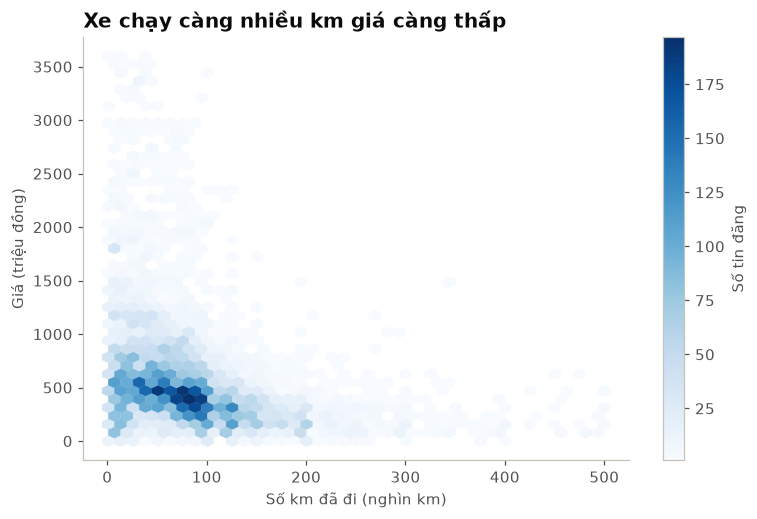

Hệ số tương quan Spearman: -0.42


In [11]:
d = df[(df["condition_ad"] == "Đã sử dụng") & df["mileage_k"].between(1, 500)
       & (df["price_tr"] <= df["price_tr"].quantile(0.99))]

fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(d["mileage_k"], d["price_tr"], gridsize=40, cmap="Blues", mincnt=1, linewidths=0.2)
cb = fig.colorbar(hb, ax=ax)
cb.set_label("Số tin đăng")
ax.set_xlabel("Số km đã đi (nghìn km)")
ax.set_ylabel("Giá (triệu đồng)")
ax.set_title("Xe chạy càng nhiều km giá càng thấp")
ax.grid(False)
save(fig, "09_km_gia")
print("Hệ số tương quan Spearman:", round(d["mileage_k"].corr(d["price_tr"], method="spearman"), 2))

## 11. Xuất xứ

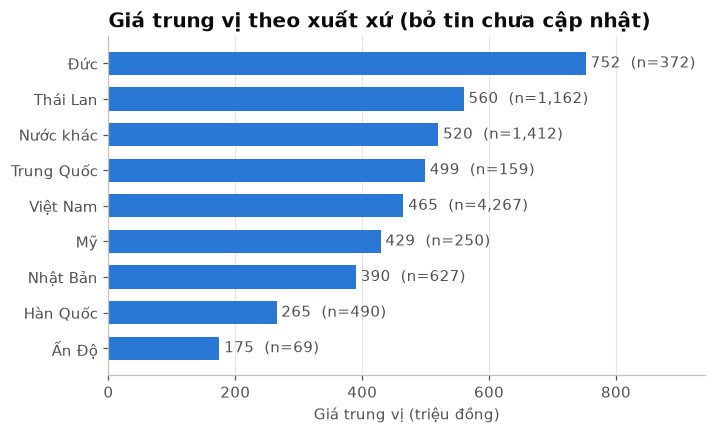

In [12]:
d = df.dropna(subset=["carorigin"])
vc = d["carorigin"].value_counts()
d = d[d["carorigin"].isin(vc[vc >= 30].index)]
g = d.groupby("carorigin")["price_tr"].agg(["median", "count"]).sort_values("median")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(g.index, g["median"], color=BLUE, height=0.65)
for y, (m, n) in enumerate(zip(g["median"], g["count"])):
    ax.text(m + g["median"].max() * 0.01, y, f"{m:,.0f}  (n={n:,})", va="center", color=INK2)
ax.set_xlim(0, g["median"].max() * 1.25)
ax.set_xlabel("Giá trung vị (triệu đồng)")
ax.set_title("Giá trung vị theo xuất xứ (bỏ tin chưa cập nhật)")
ax.grid(axis="y", visible=False)
save(fig, "10_xuat_xu")

## 12. Tương quan giữa các biến số

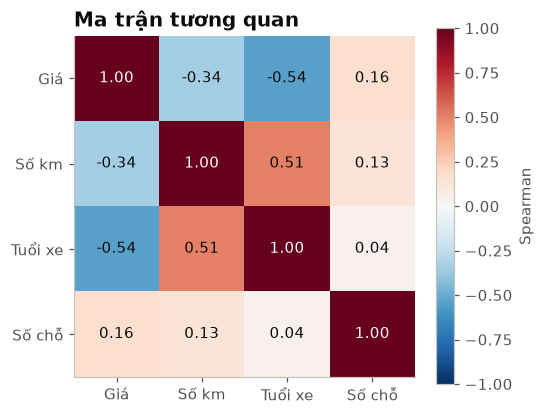

In [13]:
num = df[["price_tr", "mileage_k", "age", "carseats"]].rename(columns={
    "price_tr": "Giá", "mileage_k": "Số km", "age": "Tuổi xe", "carseats": "Số chỗ"})
c = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)))
ax.set_xticklabels(c.columns)
ax.set_yticks(range(len(c)))
ax.set_yticklabels(c.columns)
for i in range(len(c)):
    for j in range(len(c)):
        v = c.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.55 else INK)
fig.colorbar(im, ax=ax, label="Spearman")
ax.grid(False)
ax.set_title("Ma trận tương quan")
save(fig, "11_tuong_quan")

## 13. Giá trung vị theo thương hiệu và nhiên liệu
Heatmap: màu đậm = giá cao. Ô có ít hơn 10 tin để trống.

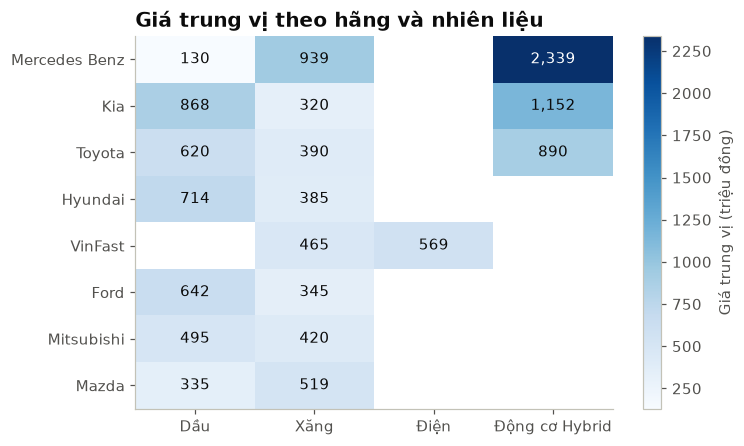

In [14]:
top8 = df["carbrand"].value_counts().head(8).index
d = df[df["carbrand"].isin(top8)]
pv = d.pivot_table(index="carbrand", columns="fuel", values="price_tr", aggfunc="median")
cnt = d.pivot_table(index="carbrand", columns="fuel", values="price_tr", aggfunc="count")
pv = pv.where(cnt >= 10).loc[:, lambda x: x.notna().any()]
pv = pv.loc[pv.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 4.4))
im = ax.imshow(pv, cmap="Blues", aspect="auto")
ax.set_xticks(range(pv.shape[1]))
ax.set_xticklabels(pv.columns)
ax.set_yticks(range(pv.shape[0]))
ax.set_yticklabels(pv.index)
vmax = np.nanmax(pv.values)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        v = pv.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", color="white" if v > vmax * 0.6 else INK)
fig.colorbar(im, ax=ax, label="Giá trung vị (triệu đồng)")
ax.grid(False)
ax.set_title("Giá trung vị theo hãng và nhiên liệu")
save(fig, "12_hang_nhien_lieu")